# 03 | Exploratory Data Analysis

## Table of Contents

1. EDA Setup
2. Credit Risk Distribution
3. Loan Purpose Analysis
4. Checking Balance Analysis
5. Savings Balance Analysis
6. Financial Status Analysis
7. Employment Duration Analysis
8. Customer Relationship Duration Analysis

In [1]:
# === EDA Setup (one setup cell that replaces the preparation steps scattered throughout your notebook; combining all the cleaning done) ===

import pandas as pd
import matplotlib.pyplot as plt

# Load both datasets
file_path = "Data/Credit_Risk_Data.xlsx"

base_df = pd.read_excel(file_path, sheet_name=0)
additional_df = pd.read_excel(file_path, sheet_name=1)

# Standardize column names
base_df.columns = base_df.columns.str.strip()
additional_df.columns = additional_df.columns.str.strip()

# Standardize gender values
base_df["Gender"] = base_df["Gender"].str.strip().str.upper()
additional_df["Gender"] = additional_df["Gender"].str.strip().str.upper()

# Create the checking balance category used in our EDA
base_df["Checking Status"] = base_df["Checking"].apply(
    lambda x: "Zero Balance" if x == 0 else "Positive Balance"
)

print("EDA datasets loaded and prepared successfully!")
print("Base Dataset:", base_df.shape)

EDA datasets loaded and prepared successfully!
Base Dataset: (425, 13)


c:\Users\selen\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
c:\Users\selen\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


# 03. Exploratory Data Analysis (EDA)

## 3.1 Credit Risk Overview

=== Credit Risk Distribution ===


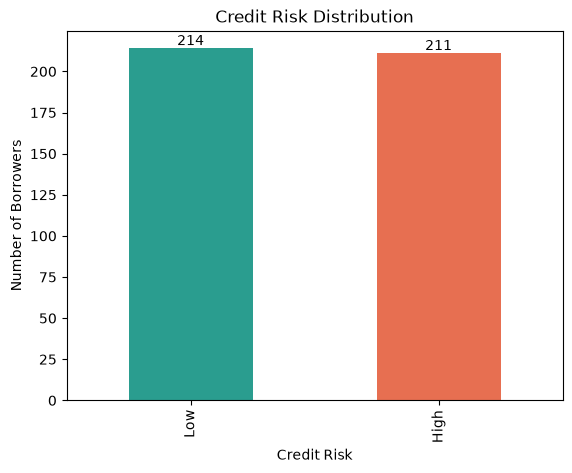

In [2]:
import matplotlib.pyplot as plt

print("=== Credit Risk Distribution ===")

# Count borrowers in each risk category
risk_counts = base_df["Credit Risk"].value_counts()

# Create a bar chart
risk_counts.plot(
    kind="bar",
    color=["#2A9D8F" if risk == "Low" else "#E76F51"
           for risk in risk_counts.index]
)

# Add chart title and axis labels
plt.title("Credit Risk Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Number of Borrowers")
plt.bar_label(plt.gca().containers[0])

# Display the chart
plt.show()

Low Risk: 214 borrowers (50.35%)
High Risk: 211 borrowers (49.65%)
The two groups are almost equally represented.

## 3.2 Loan Purpose Analysis

=== Borrowers by Loan Purpose ===


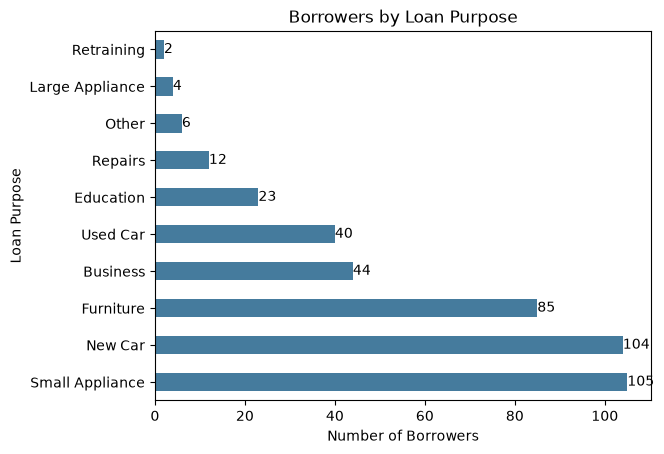

In [3]:
print("=== Borrowers by Loan Purpose ===")

# Count borrowers for each loan purpose
purpose_counts = base_df["Loan Purpose"].value_counts()

# Create a horizontal bar chart
purpose_counts.plot(
    kind="barh",
    color="#457B9D"
)

# Add chart title and axis labels
# plt.gca() = gets the current chart's axes
# .containers[0] = selects the group of bars
# plt.bar_label() = displays the count above each bar
plt.title("Borrowers by Loan Purpose")
plt.xlabel("Number of Borrowers")
plt.ylabel("Loan Purpose")
plt.bar_label(plt.gca().containers[0])

# Display the chart
plt.show()

- Small Appliance (105) and New Car (104) are the most common loan purposes.
- Furniture (85) is the third most common.
- Retraining (2) and Large Appliance (4) are the least common.

**The most common loan purpose isn't necessarily the riskiest.**

=== Credit Risk by Loan Purpose ===


Credit Risk,High,Low
Loan Purpose,,
Business,23,21
Education,14,9
Furniture,43,42
Large Appliance,3,1
New Car,65,39
Other,4,2
Repairs,4,8
Retraining,1,1
Small Appliance,42,63


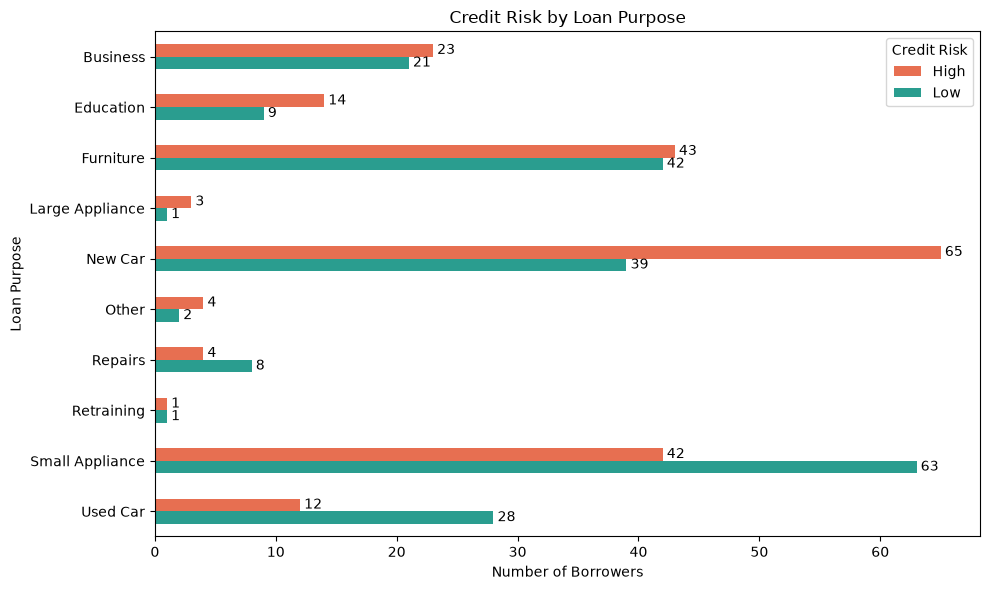

In [4]:
print("=== Credit Risk by Loan Purpose ===")

# Count borrowers by loan purpose and credit risk
# pd.crosstab() = counts combinations of two categorical variables
# .sort_index() = sorts loan purposes alphabetically
risk_by_purpose = pd.crosstab(
    base_df["Loan Purpose"],
    base_df["Credit Risk"]
).sort_index()

# Display the frequency table
display(risk_by_purpose)

# Create a grouped horizontal bar chart
risk_by_purpose.plot(
    kind="barh",
    figsize=(10, 6),
    color=["#E76F51", "#2A9D8F"]
)

# Add chart title and axis labels
plt.title("Credit Risk by Loan Purpose")
plt.xlabel("Number of Borrowers")
plt.ylabel("Loan Purpose")
plt.legend(title="Credit Risk")

# Add count labels to both risk categories
# .containers = groups of bars
# padding=3 = space between bars and labels
for container in plt.gca().containers:
    plt.bar_label(container, padding=3)

# Display loan purposes alphabetically from top to bottom
plt.gca().invert_yaxis()

# Adjust layout and display chart
plt.tight_layout()
plt.show()

**Observation: Credit Risk by Loan Purpose**

Although Small Appliance has more high-risk borrowers (42) than Education (14), Education actually has a higher percentage of high-risk borrowers (60.9% compared to 40.0%).

This shows why looking at counts alone can be misleading. The number of high-risk borrowers tells us how many there are, while the percentage helps us understand how common high risk is within each loan purpose.

For our dashboard, both are important when comparing credit risk across different customer groups. However, we should also consider the sample size, since Education only has 23 borrowers.

=== High Risk Rate by Loan Purpose ===


Credit Risk,High,Low,Total,High Risk Rate (%)
Loan Purpose,,,,
Large Appliance,3,1,4,75.00
Other,4,2,6,66.67
New Car,65,39,104,62.50
Education,14,9,23,60.87
Business,23,21,44,52.27
Furniture,43,42,85,50.59
Retraining,1,1,2,50.00
Small Appliance,42,63,105,40.00
Repairs,4,8,12,33.33


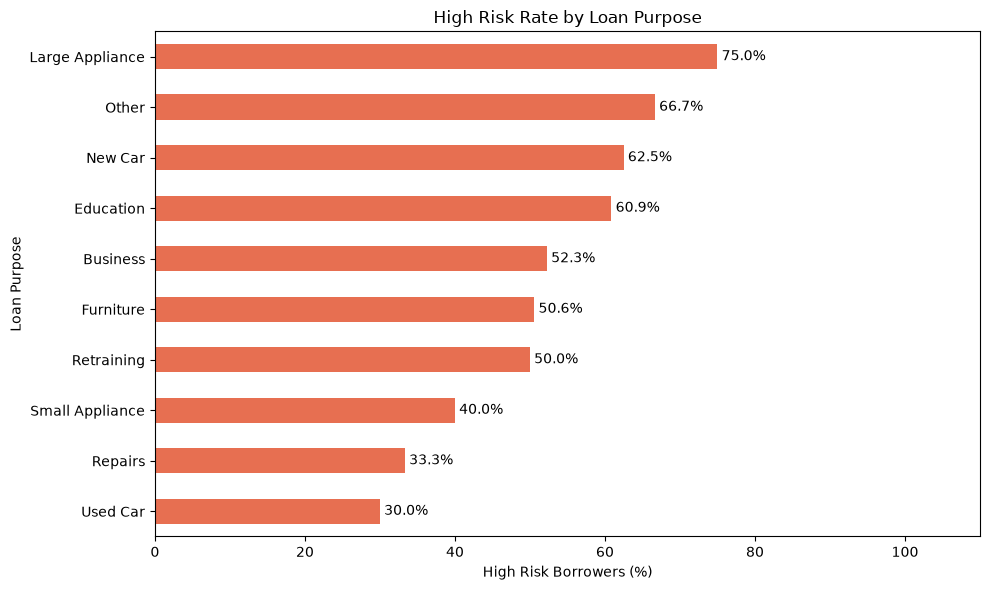

In [5]:
print("=== High Risk Rate by Loan Purpose ===")

# Count High Risk and Low Risk borrowers for each loan purpose
# pd.crosstab() = counts combinations of two categorical variables
risk_by_purpose = pd.crosstab(
    base_df["Loan Purpose"],
    base_df["Credit Risk"]
)

# Calculate the total number of borrowers for each loan purpose
risk_by_purpose["Total"] = risk_by_purpose.sum(axis=1)

# Calculate the High Risk percentage
# / = divides High Risk count by total borrowers
# * 100 = converts proportions to percentages
# .sort_values(ascending=False) = sorts from highest to lowest
risk_by_purpose["High Risk Rate (%)"] = (
    risk_by_purpose["High"] / risk_by_purpose["Total"] * 100
)

risk_by_purpose = risk_by_purpose.sort_values(
    "High Risk Rate (%)", ascending=False
)

# Display the table with counts and percentages
display(risk_by_purpose.round(2))

# Create a horizontal bar chart
ax = risk_by_purpose["High Risk Rate (%)"].plot(
    kind="barh",
    figsize=(10, 6),
    color="#E76F51"
)

# Add percentage labels to each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

# Add chart title and axis labels
plt.title("High Risk Rate by Loan Purpose")
plt.xlabel("High Risk Borrowers (%)")
plt.ylabel("Loan Purpose")
plt.xlim(0, 110)

# Display highest percentage at the top
plt.gca().invert_yaxis()

# Adjust layout and display chart
plt.tight_layout()
plt.show()

**Observation: High Risk Rate by Loan Purpose**

Large Appliance has the highest high-risk rate at 75%, followed by New Car (62.5%) and Education (60.9%). Used Car has the lowest rate at 30%.

However, Large Appliance only has 4 borrowers, while New Car has 104. This means we should be careful when interpreting the 75% risk rate because it's based on a very small sample.

New Car may deserve more attention from management because it has both a relatively high risk rate and a larger number of borrowers.

This shows why we need to consider both percentages and sample sizes when evaluating credit risk. A higher percentage doesn't always mean a category should be our biggest priority.

*(The High Risk Percentage is calculated by dividing the number of high-risk borrowers by the total number of borrowers within each loan purpose, then multiplying by 100.)*

## 3.3 Financial Factors

=== Checking Balance by Credit Risk ===


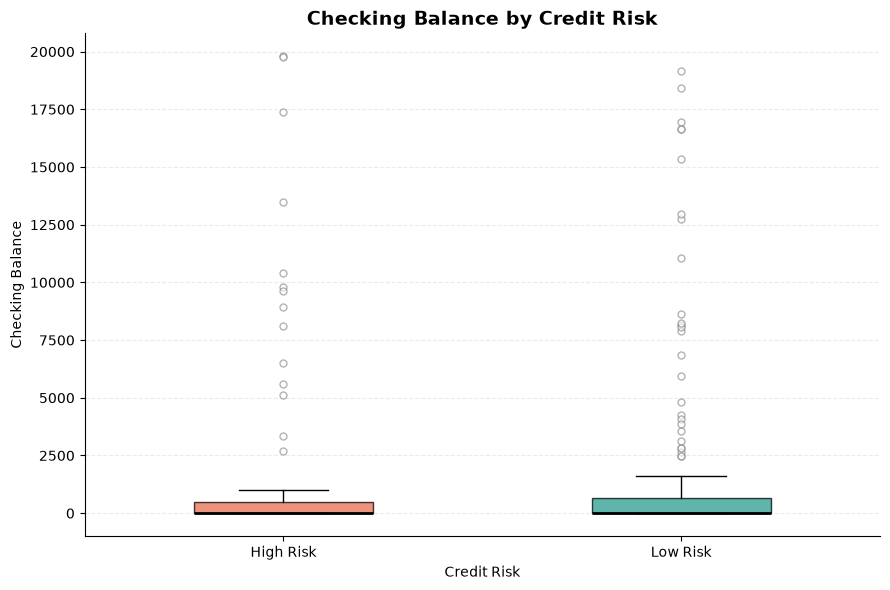

In [6]:
print("=== Checking Balance by Credit Risk ===")

# .boxplot() = creates a box plot to compare numerical distributions
# column="Checking" = selects the numerical variable we're examining
# by="Credit Risk" = separates borrowers into High and Low risk groups
# plt.suptitle("") = removes the extra title Pandas automatically generates

# Remove extra spaces from column names (Data shows that the column name has an extra space)
# .str.strip() = removes spaces at the beginning and end of text
base_df.columns = base_df.columns.str.strip()
additional_df.columns = additional_df.columns.str.strip()


# Create a box plot with customized colors
fig, ax = plt.subplots(figsize=(9, 6))

# Separate checking balances by credit risk
checking_data = [
    base_df.loc[base_df["Credit Risk"] == "High", "Checking"],
    base_df.loc[base_df["Credit Risk"] == "Low", "Checking"]
]

# Create box plots with outliers displayed
bp = ax.boxplot(
    checking_data,
    tick_labels=["High Risk", "Low Risk"],
    patch_artist=True,
    widths=0.45,
    medianprops=dict(color="black", linewidth=2),
    flierprops=dict(marker="o", markerfacecolor="white",
                    markeredgecolor="gray", markersize=5, alpha=0.6)
)

# Set different colors for each risk category
colors = ["#E76F51", "#2A9D8F"]

for box, color in zip(bp["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.75)

# Add chart title and axis labels
ax.set_title("Checking Balance by Credit Risk", fontsize=14, fontweight="bold")
ax.set_xlabel("Credit Risk")
ax.set_ylabel("Checking Balance")

# Add subtle horizontal gridlines
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Display chart
plt.tight_layout()
plt.show()

In [7]:
base_df.groupby("Credit Risk")["Checking"].median()

Credit Risk
High    0.0
Low     0.0
Name: Checking, dtype: float64

**Observation: Checking Balance by Credit Risk**

Both High Risk and Low Risk borrowers have a median checking balance of 0, meaning at least half of the borrowers in each group have no checking balance.

The box plot also shows that checking balances are highly right-skewed, with most borrowers having relatively low balances and a few having extremely high balances. The Low Risk group appears to have a slightly wider spread, but the two groups overlap considerably.

Based on this visualization, checking balance alone does not clearly distinguish between High Risk and Low Risk borrowers. It would be interesting to further examine whether having a zero checking balance is associated with a higher risk rate compared to having a positive balance.

=== High Risk Rate by Checking Balance Status ===


Credit Risk,High,Low,Total,High Risk Rate (%)
Checking Status,,,,
Zero Balance,128,123,251,51.0
Positive Balance,83,91,174,47.7


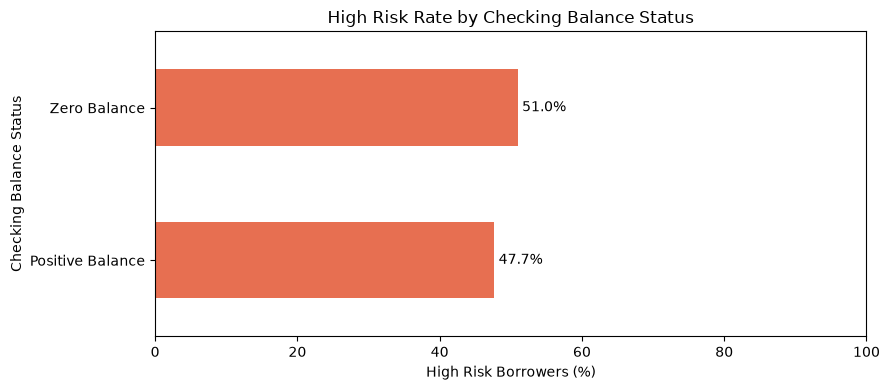

In [8]:
print("=== High Risk Rate by Checking Balance Status ===")

# Create a new category based on checking balance to divide borrowers into two groups: those with zero balance and those with a positive balance
# .apply() = applies a function to each value
# lambda = a short function
base_df["Checking Status"] = base_df["Checking"].apply(
    lambda x: "Zero Balance" if x == 0 else "Positive Balance"
)

# Count High Risk and Low Risk borrowers in each category
checking_risk = pd.crosstab(
    base_df["Checking Status"],
    base_df["Credit Risk"]
)

# Calculate total borrowers and high-risk percentage
checking_risk["Total"] = checking_risk.sum(axis=1)

checking_risk["High Risk Rate (%)"] = (
    checking_risk["High"] / checking_risk["Total"] * 100
)

# Sort by highest risk rate
checking_risk = checking_risk.sort_values(
    "High Risk Rate (%)", ascending=False
)

# Display the table
display(checking_risk.round(2))

# Create a horizontal bar chart
ax = checking_risk["High Risk Rate (%)"].plot(
    kind="barh",
    figsize=(9, 4),
    color="#E76F51"
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

# Add chart title and axis labels
plt.title("High Risk Rate by Checking Balance Status")
plt.xlabel("High Risk Borrowers (%)")
plt.ylabel("Checking Balance Status")
plt.xlim(0, 100)

# Show highest risk rate at the top
ax.invert_yaxis()

plt.tight_layout()
plt.show()

**Observation: High Risk Rate by Checking Balance Status**

Borrowers with zero checking balances have a slightly higher high-risk rate (51.0%) compared to those with positive balances (47.7%). However, the difference is only about 3.3 percentage points.

This suggests that having a positive checking balance does not necessarily indicate lower credit risk. Since the difference is relatively small, checking balance status alone may not be very useful for distinguishing between high-risk and low-risk borrowers.

It would be worth exploring whether the actual balance amount, rather than simply having a zero or positive balance, provides more meaningful information.

=== Savings Balance by Credit Risk ===


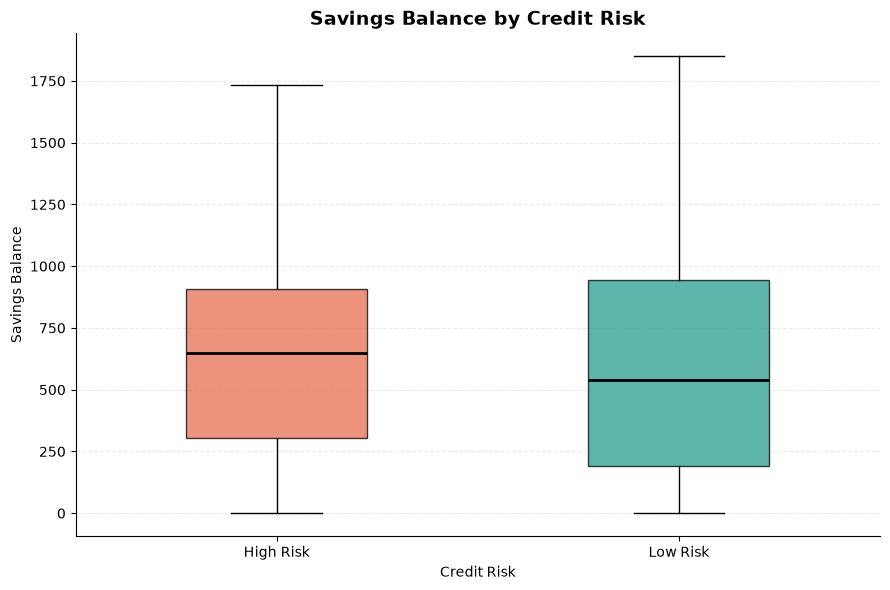

In [9]:
print("=== Savings Balance by Credit Risk ===")

# Separate savings balances by credit risk
savings_data = [
    base_df.loc[base_df["Credit Risk"] == "High", "Savings"],
    base_df.loc[base_df["Credit Risk"] == "Low", "Savings"]
]

# Create a box plot with outliers hidden for better readability
# showfliers=False = hides outlier circles without removing data
fig, ax = plt.subplots(figsize=(9, 6))

bp = ax.boxplot(
    savings_data,
    tick_labels=["High Risk", "Low Risk"],
    patch_artist=True,
    widths=0.45,
    showfliers=False,
    medianprops=dict(color="black", linewidth=2)
)

# Apply consistent colors
# Coral = High Risk; Teal = Low Risk
colors = ["#E76F51", "#2A9D8F"]

for box, color in zip(bp["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.75)

# Add chart title and axis labels
ax.set_title("Savings Balance by Credit Risk", fontsize=14, fontweight="bold")
ax.set_xlabel("Credit Risk")
ax.set_ylabel("Savings Balance")

# Add subtle gridlines
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Adjust layout and display chart
plt.tight_layout()
plt.show()

**Observation: Savings Balance by Credit Risk**

High Risk borrowers have a slightly higher median savings balance (approximately $650) compared to Low Risk borrowers (approximately $540).

Low Risk borrowers show a wider spread in savings balances, suggesting greater variability within this group.

Both groups have considerable overlap, making it difficult to distinguish credit risk based on savings alone.

Outliers were hidden in the visualization for better readability, but all observations remain in the dataset.

Interestingly, having higher savings does not necessarily correspond to lower credit risk in this dataset. Other factors may play a more important role in determining credit risk.

## 3.4 Demographic Factors

=== Age by Credit Risk ===


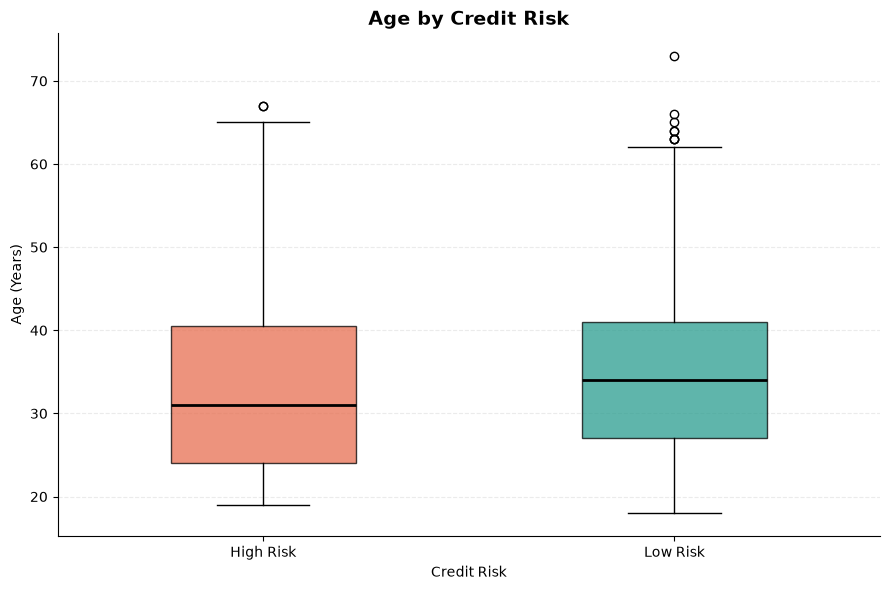

In [10]:
print("=== Age by Credit Risk ===")

# Separate ages by credit risk
age_data = [
    base_df.loc[base_df["Credit Risk"] == "High", "Age"],
    base_df.loc[base_df["Credit Risk"] == "Low", "Age"]
]

# Create a box plot
fig, ax = plt.subplots(figsize=(9, 6))

bp = ax.boxplot(
    age_data,
    tick_labels=["High Risk", "Low Risk"],
    patch_artist=True,
    widths=0.45,
    medianprops=dict(color="black", linewidth=2)
)

# Apply consistent colors
colors = ["#E76F51", "#2A9D8F"]

for box, color in zip(bp["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.75)

# Add chart title and axis labels
ax.set_title("Age by Credit Risk", fontsize=14, fontweight="bold")
ax.set_xlabel("Credit Risk")
ax.set_ylabel("Age (Years)")

# Add subtle gridlines
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Observation: Age by Credit Risk**

High Risk borrowers tend to be slightly younger, with a median age of approximately 31 compared to 34 for Low Risk borrowers.

Both groups have similar age distributions, with considerable overlap.

The Low Risk group has more outliers among older borrowers, although both groups include borrowers across a wide age range.

Overall, age may have some relationship with credit risk, but the small difference suggests it should be considered alongside other factors rather than independently.

(So far, we've seen that High Risk borrowers have slightly higher median savings but lower median ages. This is why examining multiple variables together will be important later in the analysis.)

## 3.5 Employment & Customer Relationships

=== Months Employed by Credit Risk ===


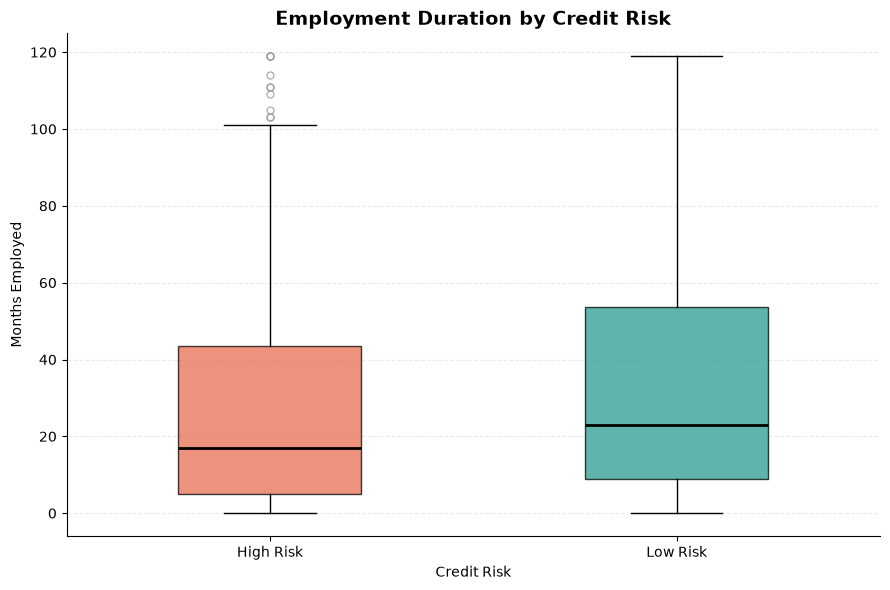

In [11]:
print("=== Months Employed by Credit Risk ===")

# Separate employment duration by credit risk
employment_data = [
    base_df.loc[base_df["Credit Risk"] == "High", "Months Employed"],
    base_df.loc[base_df["Credit Risk"] == "Low", "Months Employed"]
]

# Create a box plot with outliers displayed
fig, ax = plt.subplots(figsize=(9, 6))

bp = ax.boxplot(
    employment_data,
    tick_labels=["High Risk", "Low Risk"],
    patch_artist=True,
    widths=0.45,
    medianprops=dict(color="black", linewidth=2),
    flierprops=dict(
        marker="o",
        markerfacecolor="white",
        markeredgecolor="gray",
        markersize=5,
        alpha=0.6
    )
)

# Apply consistent colors
colors = ["#E76F51", "#2A9D8F"]

for box, color in zip(bp["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.75)

# Add chart title and axis labels
ax.set_title("Employment Duration by Credit Risk", fontsize=14, fontweight="bold")
ax.set_xlabel("Credit Risk")
ax.set_ylabel("Months Employed")

# Add subtle gridlines
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Observation: Employment Duration by Credit Risk**

Low Risk borrowers have a higher median employment duration (approximately 23 months) compared to High Risk borrowers (approximately 17 months).

The Low Risk group also shows greater variability in employment duration.

Although the distributions overlap, borrowers with longer employment histories appear somewhat more likely to fall into the Low Risk group.

Several High Risk borrowers have unusually long employment durations, showing that employment stability alone does not determine credit risk.

Employment duration may be a useful factor to consider alongside other financial and demographic variables.

(Interesting finding: Employment duration appears to be a potentially useful indicator for our credit risk analysis.)

=== Customer Relationship Duration by Credit Risk ===


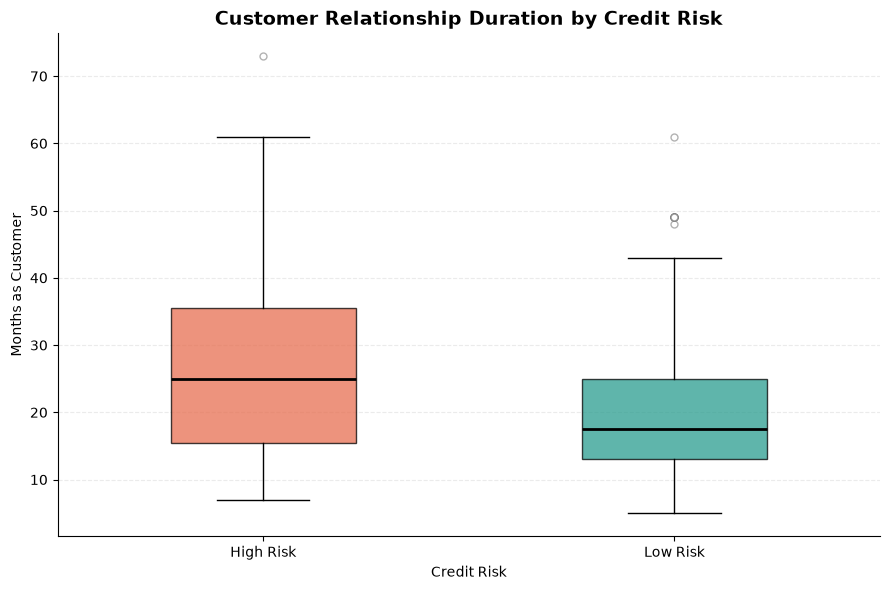

In [12]:
print("=== Customer Relationship Duration by Credit Risk ===")

# Separate customer relationship duration by credit risk
customer_data = [
    base_df.loc[base_df["Credit Risk"] == "High", "Months Customer"],
    base_df.loc[base_df["Credit Risk"] == "Low", "Months Customer"]
]

# Create a box plot
fig, ax = plt.subplots(figsize=(9, 6))

bp = ax.boxplot(
    customer_data,
    tick_labels=["High Risk", "Low Risk"],
    patch_artist=True,
    widths=0.45,
    medianprops=dict(color="black", linewidth=2),
    flierprops=dict(
        marker="o",
        markerfacecolor="white",
        markeredgecolor="gray",
        markersize=5,
        alpha=0.6
    )
)

# Apply consistent colors
colors = ["#E76F51", "#2A9D8F"]

for box, color in zip(bp["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.75)

# Add chart title and axis labels
ax.set_title("Customer Relationship Duration by Credit Risk",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Credit Risk")
ax.set_ylabel("Months as Customer")

# Add subtle gridlines
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Observation: Customer Relationship Duration by Credit Risk**

High Risk borrowers have a longer median customer relationship (approximately 25 months) compared to Low Risk borrowers (approximately 17–18 months).

High Risk borrowers also show greater variability in how long they have been customers.

Interestingly, longer customer relationships do not necessarily correspond to lower credit risk in this dataset.

Both groups overlap, suggesting that relationship duration alone is not enough to determine a borrower's risk level.

This finding challenges the assumption that longer-standing customers are always less risky and highlights the importance of examining multiple factors when making credit decisions.

(Employment duration and customer relationship duration show different patterns.)

## 3.6 Housing & Job Analysis

=== High Risk Rate by Housing Type ===


Credit Risk,High,Low,Total,High Risk Rate (%)
Housing,,,,
Own,131,161,292,44.863014
Other,31,21,52,59.615385
Rent,49,32,81,60.493827


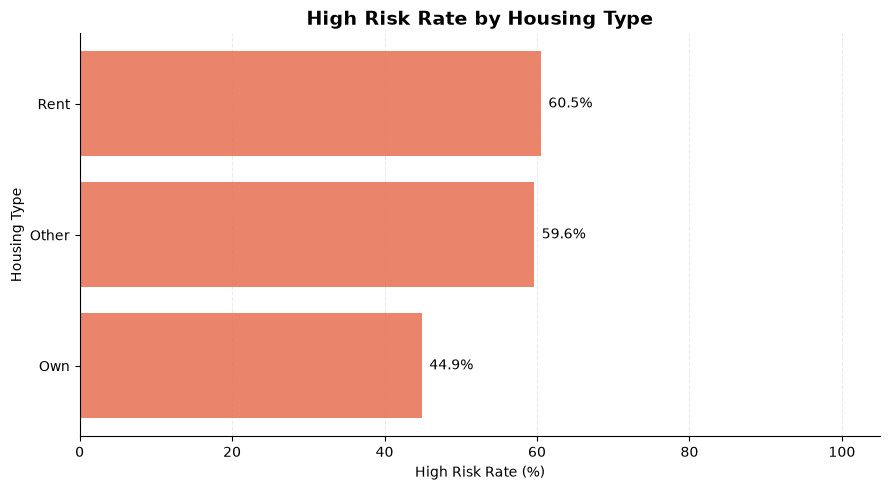

In [13]:
print("=== High Risk Rate by Housing Type ===")

# Count High Risk and Low Risk borrowers for each housing type
housing_risk = pd.crosstab(
    base_df["Housing"],
    base_df["Credit Risk"]
)

# Calculate total borrowers and percentage of High Risk borrowers
housing_risk["Total"] = housing_risk["High"] + housing_risk["Low"]
housing_risk["High Risk Rate (%)"] = (
    housing_risk["High"] / housing_risk["Total"] * 100
)

# Sort housing types by High Risk Rate
housing_risk = housing_risk.sort_values(
    "High Risk Rate (%)", ascending=True
)

# Display the summary table
display(housing_risk)

# Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    housing_risk.index,
    housing_risk["High Risk Rate (%)"],
    color="#E76F51",
    alpha=0.85
)

# Add percentage labels to each bar
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}%",
        va="center"
    )

# Add title and axis labels
ax.set_title("High Risk Rate by Housing Type",
             fontsize=14, fontweight="bold")
ax.set_xlabel("High Risk Rate (%)")
ax.set_ylabel("Housing Type")
ax.set_xlim(0, 105)

# Improve readability
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Observation: High Risk Rate by Housing Type**

Renters have the highest High Risk rate at 60.5%, followed closely by the Other housing category at 59.6%.

Homeowners have the lowest High Risk rate at 44.9%, suggesting a possible relationship between housing type and credit risk.

Although homeowners have the most High Risk borrowers in absolute numbers, they also represent the largest group in the dataset.

Comparing percentages rather than counts gives us a better understanding of risk differences across housing categories.

Housing type may be useful for understanding customer segments, but it should not be used alone to make credit decisions.

=== High Risk Rate by Job Type ===


Credit Risk,High,Low,Total,High Risk Rate (%)
Job,,,,
Unemployed,5,6,11,45.5
Unskilled,43,46,89,48.3
Skilled,135,136,271,49.8
Management,28,26,54,51.9


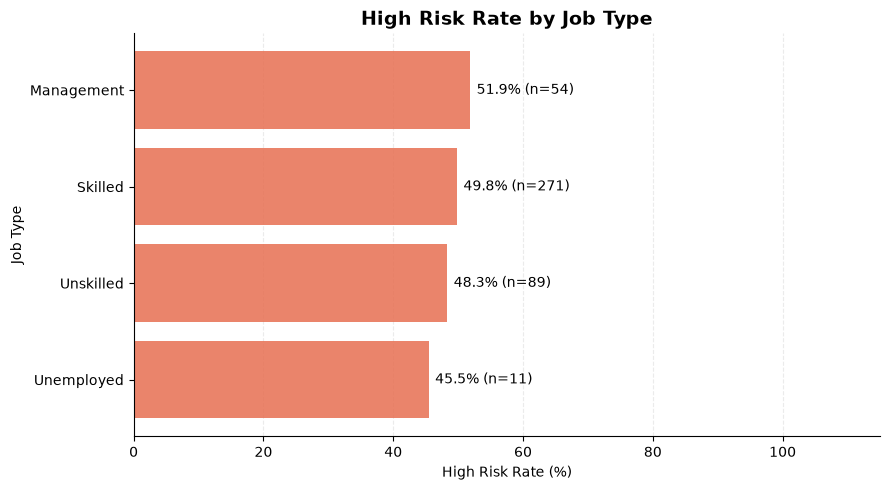

In [14]:
print("=== High Risk Rate by Job Type ===")

# Count High Risk and Low Risk borrowers by job type
job_risk = pd.crosstab(
    base_df["Job"],
    base_df["Credit Risk"]
)

# Calculate total borrowers and High Risk percentage
job_risk["Total"] = job_risk["High"] + job_risk["Low"]
job_risk["High Risk Rate (%)"] = (
    job_risk["High"] / job_risk["Total"] * 100
)

# Sort by High Risk Rate
job_risk = job_risk.sort_values(
    "High Risk Rate (%)", ascending=True
)

# Display summary table
display(job_risk.round(1))

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    job_risk.index,
    job_risk["High Risk Rate (%)"],
    color="#E76F51",
    alpha=0.85
)

# Add percentage and sample size labels
for bar, total in zip(bars, job_risk["Total"]):
    width = bar.get_width()
    ax.text(
        width + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}% (n={total})",
        va="center"
    )

# Add title and axis labels
ax.set_title("High Risk Rate by Job Type",
             fontsize=14, fontweight="bold")
ax.set_xlabel("High Risk Rate (%)")
ax.set_ylabel("Job Type")
ax.set_xlim(0, 115)

# Improve readability
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Observation: High Risk Rate by Job Type**

High Risk rates are relatively similar across all job categories, ranging from 45.5% to 51.9%.

Management has the highest rate at 51.9%, while Unemployed has the lowest at 45.5%.

The Skilled category contains the largest number of borrowers (271), but its High Risk rate is close to 50%.

The Unemployed category has a small sample size of only 11 borrowers, making its percentage less reliable for comparison.

Overall, job type does not appear to strongly distinguish between High Risk and Low Risk borrowers in this dataset. Employment duration may provide more useful information than job category alone.

## 3.7 Marital Status & Gender Analysis

=== High Risk Rate by Marital Status ===


Credit Risk,High,Low,Total,High Risk Rate (%)
Marital Status,,,,
Single,103,130,233,44.2
Married,17,19,36,47.2
Divorced,91,65,156,58.3


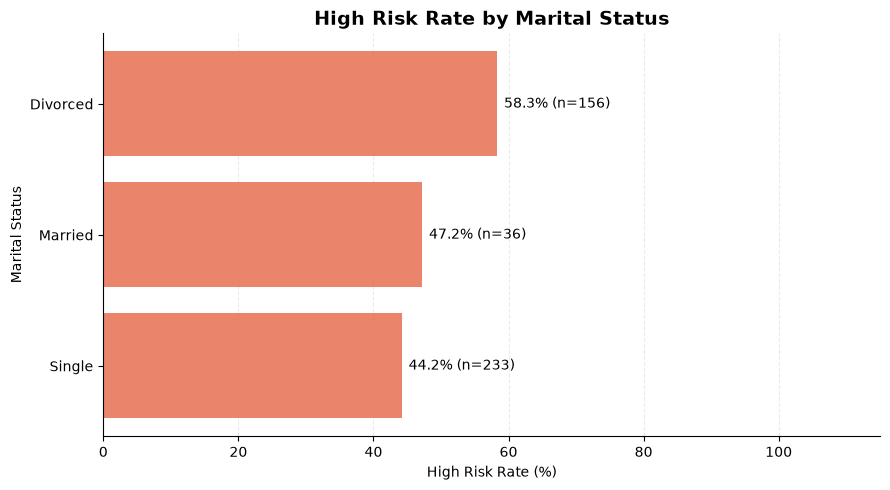

In [15]:
print("=== High Risk Rate by Marital Status ===")

# Count High Risk and Low Risk borrowers by marital status
marital_risk = pd.crosstab(
    base_df["Marital Status"],
    base_df["Credit Risk"]
)

# Calculate total borrowers and High Risk percentage
marital_risk["Total"] = marital_risk["High"] + marital_risk["Low"]
marital_risk["High Risk Rate (%)"] = (
    marital_risk["High"] / marital_risk["Total"] * 100
)

# Sort by High Risk Rate
marital_risk = marital_risk.sort_values(
    "High Risk Rate (%)", ascending=True
)

# Display summary table
display(marital_risk.round(1))

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    marital_risk.index,
    marital_risk["High Risk Rate (%)"],
    color="#E76F51",
    alpha=0.85
)

# Add percentage and sample size labels
for bar, total in zip(bars, marital_risk["Total"]):
    width = bar.get_width()
    ax.text(
        width + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}% (n={total})",
        va="center"
    )

# Add chart title and axis labels
ax.set_title("High Risk Rate by Marital Status",
             fontsize=14, fontweight="bold")
ax.set_xlabel("High Risk Rate (%)")
ax.set_ylabel("Marital Status")
ax.set_xlim(0, 115)

# Improve readability
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Observation: High Risk Rate by Marital Status**

Divorced borrowers have the highest High Risk rate at 58.3%, followed by Married borrowers at 47.2%.

Single borrowers have the lowest High Risk rate at 44.2%, despite representing the largest group in the dataset (233 borrowers).

The difference between Single and Divorced borrowers is approximately 14.1 percentage points, which is noticeably larger than the differences observed across job categories.

This suggests an association between marital status and credit risk in our dataset, but it does not establish a causal relationship.

Since marital status is a protected characteristic in lending, this analysis is more appropriate for understanding potential disparities and evaluating fairness than for making lending decisions.

=== High Risk Rate by Gender ===


Credit Risk,High,Low,Total,High Risk Rate (%)
Gender,,,,
M,133,157,290,45.9
F,78,57,135,57.8


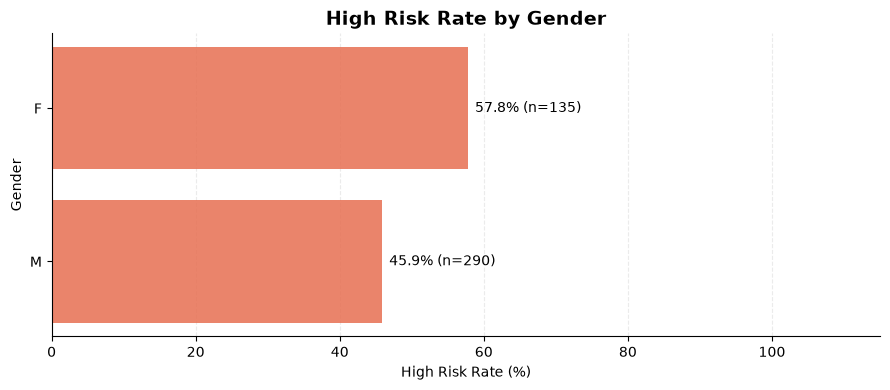

In [16]:
print("=== High Risk Rate by Gender ===")

# Count High Risk and Low Risk borrowers by gender
gender_risk = pd.crosstab(
    base_df["Gender"],
    base_df["Credit Risk"]
)

# Calculate total borrowers and High Risk percentage
gender_risk["Total"] = gender_risk["High"] + gender_risk["Low"]
gender_risk["High Risk Rate (%)"] = (
    gender_risk["High"] / gender_risk["Total"] * 100
)

# Sort by High Risk Rate
gender_risk = gender_risk.sort_values(
    "High Risk Rate (%)", ascending=True
)

# Display summary table
display(gender_risk.round(1))

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.barh(
    gender_risk.index,
    gender_risk["High Risk Rate (%)"],
    color="#E76F51",
    alpha=0.85
)

# Add percentage and sample size labels
for bar, total in zip(bars, gender_risk["Total"]):
    width = bar.get_width()
    ax.text(
        width + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}% (n={total})",
        va="center"
    )

# Add chart title and axis labels
ax.set_title("High Risk Rate by Gender",
             fontsize=14, fontweight="bold")
ax.set_xlabel("High Risk Rate (%)")
ax.set_ylabel("Gender")
ax.set_xlim(0, 115)

# Improve readability
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Observation: High Risk Rate by Gender**

Female borrowers have a higher High Risk rate at 57.8%, compared to 45.9% for male borrowers.

The difference is approximately 11.9 percentage points, suggesting a noticeable disparity between the two groups.

Male borrowers represent the majority of the dataset (290 out of 425), but their High Risk rate is lower.

This difference does not necessarily mean gender itself explains credit risk. Other financial or demographic factors may contribute to the pattern.

Since gender is a protected characteristic in lending, this finding is particularly important for fairness analysis. We should investigate whether the risk classifications reflect potential bias or differences in other variables before drawing conclusions.

## 3.8 Years Analysis

In [17]:
print("=== Years Variable Overview ===")

# Check the number of borrowers in each category
print("Years Distribution:")
display(base_df["Years"].value_counts().sort_index())

# Check how Years relates to credit risk
print("Credit Risk by Years:")
display(
    pd.crosstab(
        base_df["Years"],
        base_df["Credit Risk"],
        margins=True
    )
)

=== Years Variable Overview ===
Years Distribution:


Years
1     53
2    131
3     72
4    169
Name: count, dtype: int64

Credit Risk by Years:


Credit Risk,High,Low,All
Years,,,
1,23,30,53
2,66,65,131
3,31,41,72
4,91,78,169
All,211,214,425


Category 4 has the most borrowers (169) and the highest High Risk rate (53.8%).
Category 3 has the lowest rate (43.1%).
There's no consistent increase or decrease in risk across the four values.

=== High Risk Rate by Years ===


Credit Risk,High,Low,Total,High Risk Rate (%)
Years,,,,
1,23,30,53,43.4
2,66,65,131,50.4
3,31,41,72,43.1
4,91,78,169,53.8


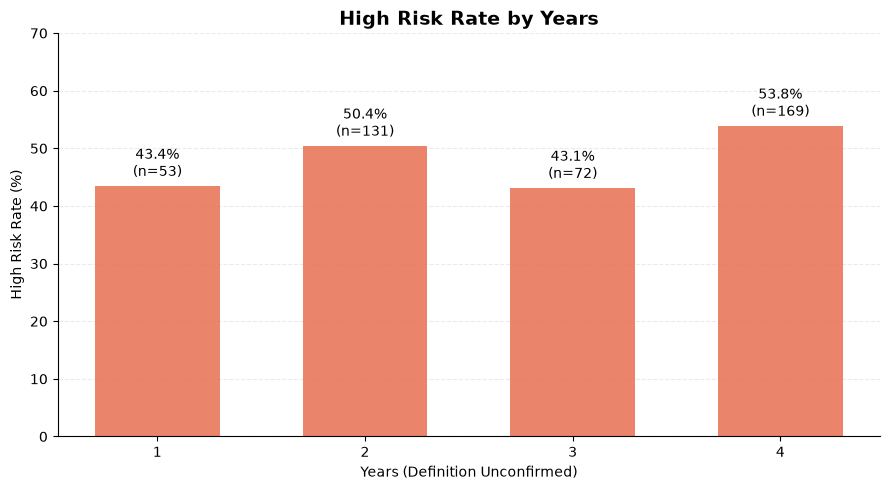

In [18]:
print("=== High Risk Rate by Years ===")

# Count borrowers by Years and Credit Risk
years_risk = pd.crosstab(base_df["Years"], base_df["Credit Risk"])

# Calculate sample sizes and High Risk rates
years_risk["Total"] = years_risk["High"] + years_risk["Low"]
years_risk["High Risk Rate (%)"] = (
    years_risk["High"] / years_risk["Total"] * 100
)

display(years_risk.round(1))

# Create chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    years_risk.index.astype(str),
    years_risk["High Risk Rate (%)"],
    color="#E76F51",
    alpha=0.85,
    width=0.6
)

# Label bars with percentages and sample sizes
for bar, total in zip(bars, years_risk["Total"]):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.1f}%\n(n={total})",
        ha="center",
        va="bottom"
    )

ax.set_title("High Risk Rate by Years", fontsize=14, fontweight="bold")
ax.set_xlabel("Years (Definition Unconfirmed)")
ax.set_ylabel("High Risk Rate (%)")
ax.set_ylim(0, 70)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Observation: High Risk Rate by Years**

Category 4 has the highest High Risk rate at 53.8% and the largest number of borrowers (169).

Category 3 has the lowest High Risk rate at 43.1%, followed closely by Category 1 at 43.4%.

High Risk rates do not consistently increase or decrease across the four categories.

The difference between the highest and lowest rates is approximately 10.7 percentage points.

Since the meaning of the Years variable is not yet confirmed, we should avoid making assumptions about what these differences represent.

The additional dataset also contains values outside the range observed in the base dataset, which should be investigated before predictive modeling.